In [9]:
import os
from itertools import cycle

import numpy as np
import torch
from torch.utils.data import Subset
import torch.nn.functional as F
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

from constants import *

In [16]:
import importlib
import constants
importlib.reload(constants)

<module 'constants' from '/zhome/79/1/232435/hess-spectrum/constants.py'>

In [13]:
DATASETS = (datasets.MNIST, datasets.FashionMNIST, datasets.CIFAR10)
OUTPUT_DIMS = (10, 10, 10)
MAX_PROP = 0.1

bar_heights = list()
for Dataset, output_dim in zip(DATASETS, OUTPUT_DIMS):
    full_trainset = Dataset(
        root=f"{DATASTORE}/{Dataset.__name__.lower()}",
        train=True, download=True, transform=transforms.ToTensor()
    )
    full_trainset.targets = torch.tensor(full_trainset.targets)
    sizes = [int(SUBSET_SIZE*(1-MAX_PROP)/(output_dim-1))]*(output_dim-1)
    sizes = [SUBSET_SIZE-sum(sizes)] + sizes
    indices = list()
    for label, size in zip(range(output_dim), sizes):
        indices += torch.where(full_trainset.targets==label)[0][:size].tolist()
    full_trainset.targets = full_trainset.targets.tolist()
    train_subset = Subset(full_trainset, indices)
    data_loader = torch.utils.data.DataLoader(train_subset, batch_size=SUBSET_SIZE)
    x, y = next(iter(data_loader))
    # Note that we work with transposed coordinates, in comparison with the theory
    x = x.view(x.size(0), -1).float().to(DEVICE)                # (n, d_0)
    y = F.one_hot(y, num_classes=output_dim).float().to(DEVICE) # (n, d_L)
    u, *_ = torch.linalg.svd(x)
    bar_heights.append(torch.linalg.matrix_norm(u.T@y, ord=2).cpu().item())

/tmp/ipykernel_2265572/2737326323.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  full_trainset.targets = torch.tensor(full_trainset.targets)


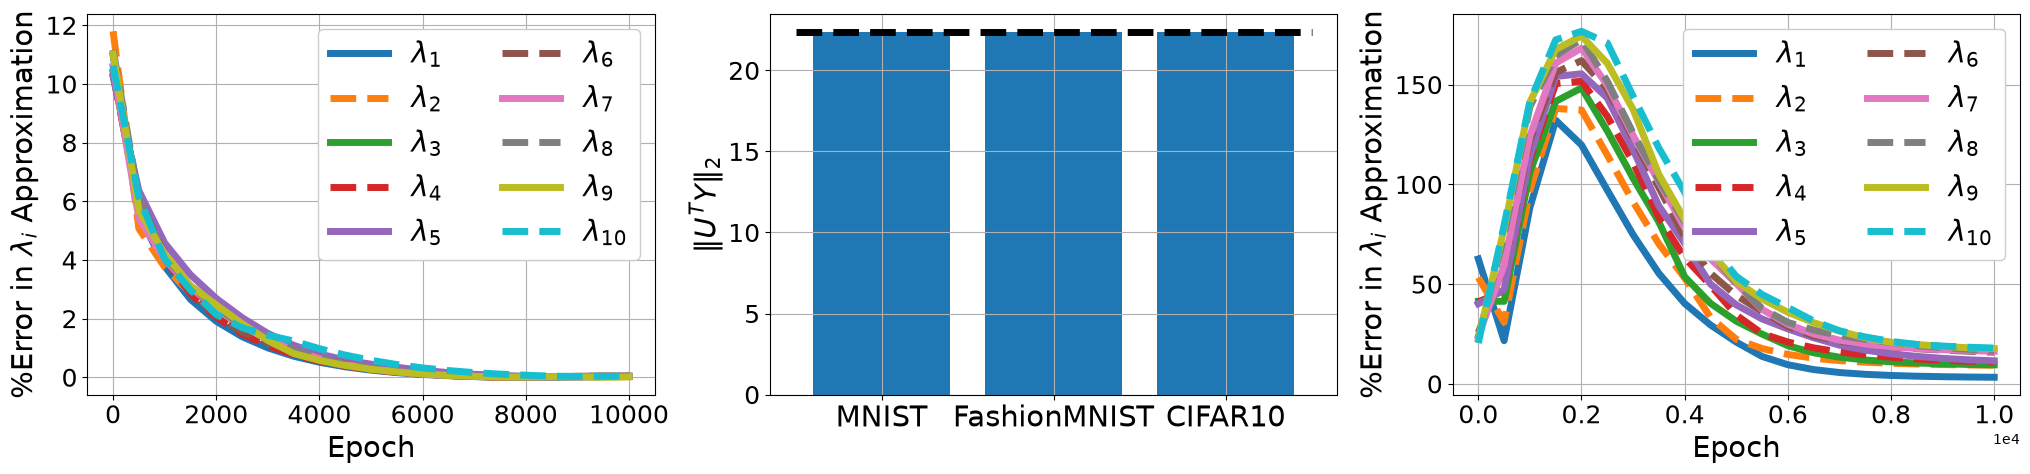

In [26]:
fig, axs = plt.subplots(1, 3, figsize=(AX_WIDTH*3, AX_HEIGHT*1))
if not hasattr(axs, "__len__"):
    axs = np.array((axs,))
    
from eigvals_error_shallow import *
source_name = "eigvals_error_shallow"
Dataset = "MNIST"
N_EIGS = 10
fn = f"{RESULTS}/{source_name}/{Dataset.lower()}.pt"
results = torch.load(fn, weights_only=False, map_location="cpu")
kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
*_, numerical_eigvals, theoretical_eigvals = out
linestyles = cycle(["-", "--"])
for i in range(min(theoretical_eigvals.shape[1], N_EIGS)):
    axs[0].plot(
        LOG_EVERY*np.arange(0, len(numerical_eigvals)),
        100*np.abs(1-theoretical_eigvals[:,i]/numerical_eigvals[:,i]),
        linewidth=5, linestyle=next(linestyles), alpha=1.0, label=rf"$\lambda_{{{i+1}}}$"
    )
axs[0].tick_params(axis="both", labelsize=constants.LABEL_SIZE)
axs[0].set_xlabel("Epoch", fontsize=constants.FONT_SIZE)
axs[0].set_ylabel(r"%Error in $\lambda_{{i}}$ Approximation", fontsize=constants.FONT_SIZE)
axs[0].grid()
axs[0].legend(loc="upper right", ncol=2, fontsize=constants.FONT_SIZE, framealpha=1.0)

width = 0.8
axs[1].bar(np.arange(len(DATASETS)), bar_heights, width=width, label=r"$\|U^T Y\|_2$")
axs[1].hlines(torch.linalg.matrix_norm(y, ord=2).cpu().item(), -0.5, 2.5, color="black", linestyle="--", linewidth=5)
axs[1].set_xticks(ticks=np.arange(len(DATASETS)), labels=list(map(lambda x: x.__name__, DATASETS)), fontsize=constants.FONT_SIZE)
axs[1].tick_params(axis="y", labelsize=constants.LABEL_SIZE)
axs[1].set_ylabel(r"$\|U^T Y\|_2$", fontsize=constants.FONT_SIZE)
axs[1].grid()

from eigvals_error_deep import *
source_name = "eigvals_error_deep"
Dataset = "MNIST"
N_EIGS = 10
fn = f"{RESULTS}/{source_name}/{Dataset.lower()}.pt"
results = torch.load(fn, weights_only=False, map_location="cpu")
kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
*_, numerical_eigvals, theoretical_eigvals = out
linestyles = cycle(["-", "--"])
for i in range(min(theoretical_eigvals.shape[1], N_EIGS)):
    axs[2].plot(
        LOG_EVERY*np.arange(0, len(numerical_eigvals)),
        100*np.abs(1-theoretical_eigvals[:,i]/numerical_eigvals[:,i]),
        linewidth=5, linestyle=next(linestyles), alpha=1.0, label=rf"$\lambda_{{{i+1}}}$"
    )
axs[2].ticklabel_format(axis="x", style="sci", scilimits=(0,0))
axs[2].tick_params(axis="both", labelsize=constants.LABEL_SIZE)
axs[2].set_xlabel("Epoch", fontsize=constants.FONT_SIZE)
axs[2].set_ylabel(r"%Error in $\lambda_{{i}}$ Approximation", fontsize=constants.FONT_SIZE)
axs[2].grid()
axs[2].legend(loc="upper right", ncol=2, fontsize=constants.FONT_SIZE, framealpha=1.0)

fig.tight_layout()
plt.show()

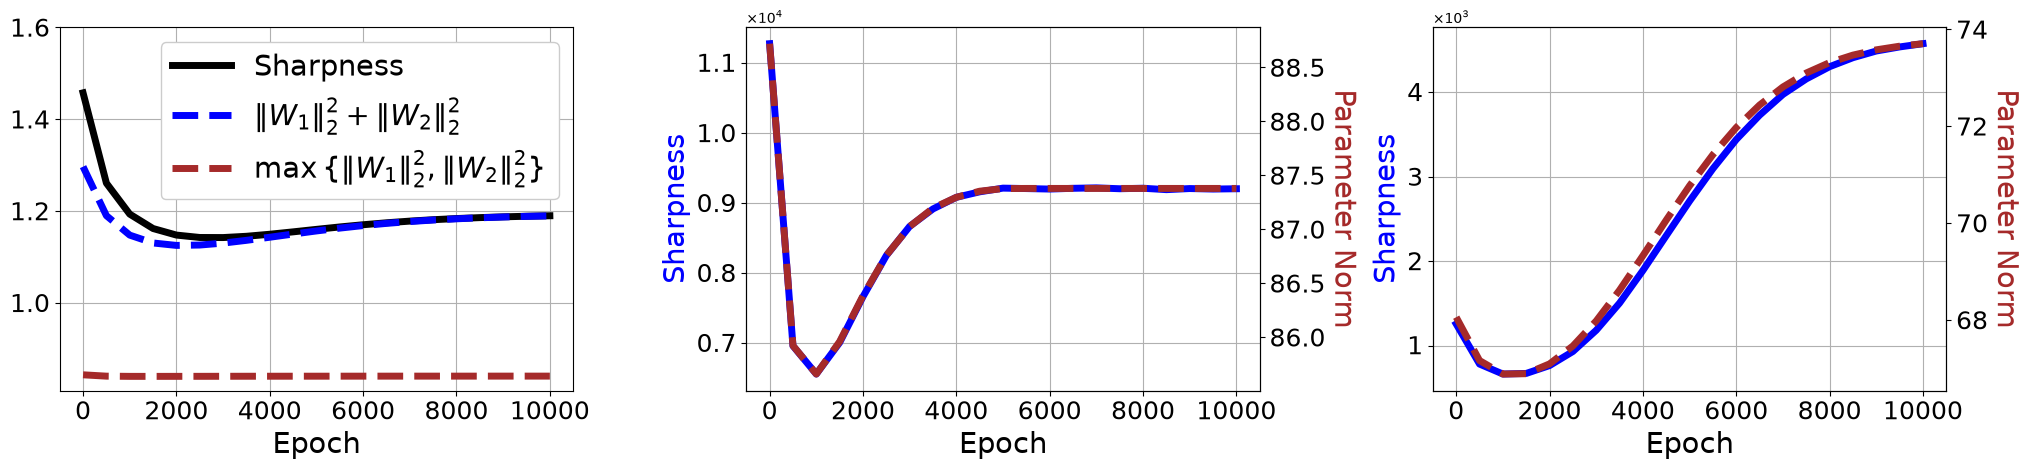

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(AX_WIDTH*3, AX_HEIGHT*1))
if not hasattr(axs, "__len__"):
    axs = np.array((axs,))
    
from comparing_bounds_shallow import *
source_name = "comparing_bounds_shallow"
DATASET = "MNIST"
fn = f"{RESULTS}/{source_name}/{Dataset.lower()}.pt"
results = torch.load(fn, weights_only=False, map_location="cpu")
kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
*_, numerical_eigvals, theoretical_eigvals = out
axs[0].plot(
    LOG_EVERY*np.arange(0, len(numerical_eigvals)),
    numerical_eigvals,
    linewidth=5, color="black", alpha=1.0, label="Sharpness"
)
axs[0].plot(
    LOG_EVERY*np.arange(0, len(theoretical_eigvals)),
    theoretical_eigvals[:,0],
    linewidth=5, linestyle="--", color="blue", alpha=1.0,
    label=r"$\|W_1\|_2^2+\|W_2\|_2^2$"
)
axs[0].plot(
    LOG_EVERY*np.arange(0, len(theoretical_eigvals)),
    theoretical_eigvals[:,1],
    linewidth=5, linestyle="--", color="brown", alpha=1.0,
    label=r"$\max\{\|W_1\|_2^2, \|W_2\|_2^2\}$"
)
axs[0].tick_params(axis="both", labelsize=LABEL_SIZE)
axs[0].set_xlabel("Epoch", fontsize=FONT_SIZE)
axs[0].set_ylim(top=1.6)
axs[0].grid()
axs[0].legend(loc="upper right", fontsize=FONT_SIZE, framealpha=1.0)

from sharpness_vs_param_norm import *
source_name = "sharpness_vs_param_norm"
SAVE_NAMES = ("wide-shallow", "narrow-deep")

for save_name, ax in zip(SAVE_NAMES, axs[1:]):
    fn = f"{RESULTS}/{source_name}/{save_name}.pt"
    results = torch.load(fn, weights_only=False, map_location="cpu")
    kwargs, assets, out = results["kwargs"], results["assets"], results["out"]
    *_, sq_param_norms, numerical_eigvals = out
    p = ax.plot(
        LOG_EVERY*np.arange(0, len(numerical_eigvals)),
        numerical_eigvals,
        linestyle="-", linewidth=5, alpha=1.0, color="blue"
    )
    ax.ticklabel_format(axis="y", style="sci", scilimits=(0,0), useMathText=True)
    ax.tick_params(axis="both", labelsize=LABEL_SIZE)
    ax.set_xlabel("Epoch", fontsize=FONT_SIZE)
    ax.set_ylabel("Sharpness", fontsize=FONT_SIZE, color=p[-1].get_color())
    ax.grid()
    ax_twin = ax.twinx()
    p = ax_twin.plot(
        LOG_EVERY*np.arange(0, len(sq_param_norms)),
        sq_param_norms.sum(axis=1),
        linestyle="--", linewidth=5, alpha=1.0, color="brown"
    )
    ax_twin.tick_params(axis="both", labelsize=LABEL_SIZE)
    ax_twin.set_ylabel("Parameter Norm", fontsize=FONT_SIZE, color=p[-1].get_color(), rotation=270, labelpad=FONT_SIZE+2)

fig.tight_layout()
plt.show()